# Lab Mid Exam: HOG vs SIFT on Blood-Cell Images
**Name:** Muhammad Junaid Mujtaba
**Registration No:** FA23-BAI-051
**Personal settings (from registration 051):** seed = 51, HOG cell = 16×16 (odd last digit), SIFT grid = 4×4 (last digit 1 is in 0–4)

## Setup: install packages

In [ ]:
!pip install medmnist opencv-python scikit-image scikit-learn matplotlib



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]


## Setup: imports and personal settings

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import Counter
from medmnist import BloodMNIST
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# ---- Personal settings (registration 051) ----
SEED = 51          # last two digits
HOG_CELL = 16      # last digit 1 is odd -> 16x16
SIFT_GRID = 4      # last digit 1 is in 0-4 -> 4x4 grid (16 keypoints)

CLASSES = [1, 5, 6, 7]
CLASS_NAMES = {1: "eosinophil", 5: "monocyte", 6: "neutrophil", 7: "platelet"}
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

## Q1. Data setup
Sampling: 160 images per class, split 100 train / 30 validation / 30 test. Grayscale, resized to 128×128.

100%|██████████| 156M/156M [00:23<00:00, 6.52MB/s]


train shape: (400, 128, 128) | class counts: {np.int64(1): 100, np.int64(5): 100, np.int64(6): 100, np.int64(7): 100}
val shape: (120, 128, 128) | class counts: {np.int64(1): 30, np.int64(5): 30, np.int64(6): 30, np.int64(7): 30}
test shape: (120, 128, 128) | class counts: {np.int64(1): 30, np.int64(5): 30, np.int64(6): 30, np.int64(7): 30}


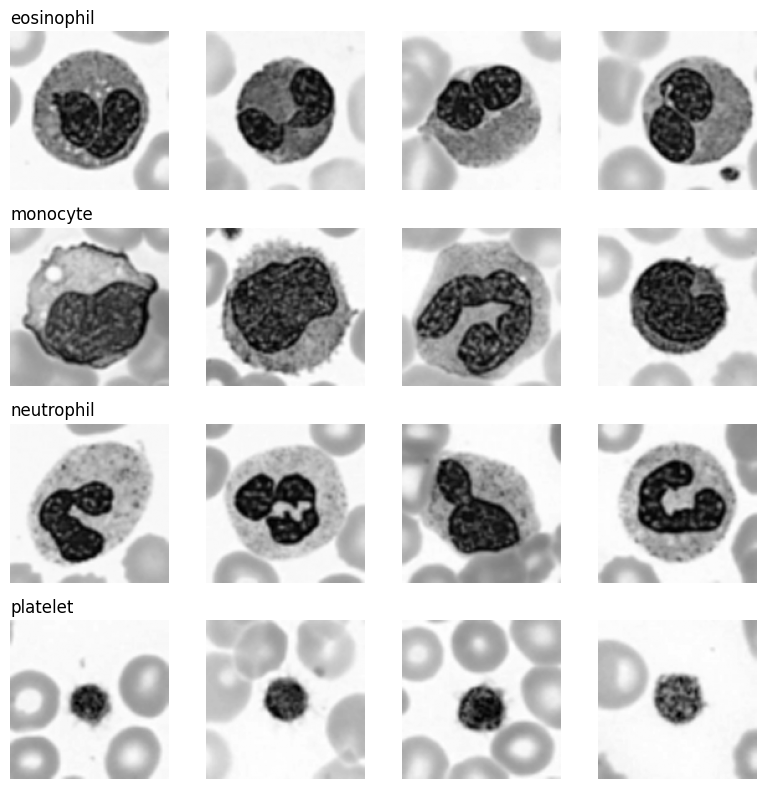

In [ ]:
# Pool all three official splits, then sample 160 per class: 100 train / 30 val / 30 test
splits = [BloodMNIST(split=s, download=True, size=64) for s in ["train", "val", "test"]]
X_all = np.concatenate([d.imgs for d in splits])
y_all = np.concatenate([d.labels.ravel() for d in splits])

def to_gray128(img_rgb):
    g = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)
    return cv2.resize(g, (128, 128), interpolation=cv2.INTER_CUBIC)

tr_X, tr_y, va_X, va_y, te_X, te_y = [], [], [], [], [], []
for c in CLASSES:
    idx = rng.permutation(np.where(y_all == c)[0])[:160]
    for i in idx[:100]:
        tr_X.append(to_gray128(X_all[i])); tr_y.append(c)
    for i in idx[100:130]:
        va_X.append(to_gray128(X_all[i])); va_y.append(c)
    for i in idx[130:160]:
        te_X.append(to_gray128(X_all[i])); te_y.append(c)

tr_X, va_X, te_X = np.array(tr_X), np.array(va_X), np.array(te_X)
tr_y, va_y, te_y = np.array(tr_y), np.array(va_y), np.array(te_y)

for name, X, y in [("train", tr_X, tr_y), ("val", va_X, va_y), ("test", te_X, te_y)]:
    print(name, "shape:", X.shape, "| class counts:", dict(Counter(y)))

# Grid: 4 examples per class
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
for r, c in enumerate(CLASSES):
    ims = tr_X[tr_y == c][:4]
    for j in range(4):
        axes[r, j].imshow(ims[j], cmap="gray"); axes[r, j].axis("off")
        if j == 0: axes[r, j].set_title(CLASS_NAMES[c], loc="left")
plt.tight_layout(); plt.show()

## Q2(a). HOG features
**Hand calculation of feature length:** 128 ÷ 16 = 8 cells per side (8×8 cells). 2×2-cell blocks with a stride of 1 cell give 7×7 = 49 blocks. Each block has 2×2 cells × 9 orientations = 36 values. Total: 49 × 36 = **1764**.

In [ ]:
def hog_feats(imgs):
    return np.array([
        hog(im, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
            cells_per_block=(2, 2), block_norm="L2-Hys")
        for im in imgs
    ])

Xtr_h, Xva_h, Xte_h = hog_feats(tr_X), hog_feats(va_X), hog_feats(te_X)
print("HOG feature length:", Xtr_h.shape[1])

HOG feature length: 1764


## Q2(b). HOG visualisation
One training image per class (top row) and its HOG picture (bottom row).

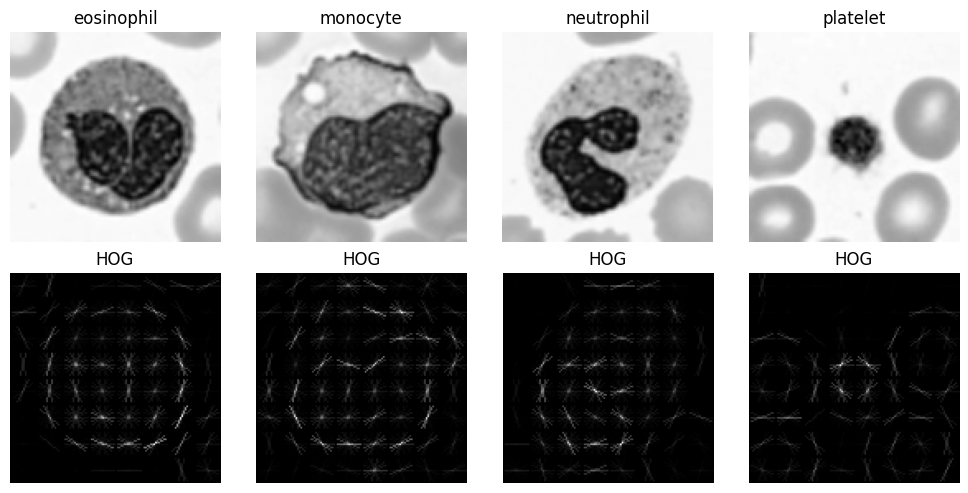

In [ ]:
# HOG visualisation: one image per class
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for j, c in enumerate(CLASSES):
    im = tr_X[tr_y == c][0]
    _, hog_img = hog(im, orientations=9, pixels_per_cell=(HOG_CELL, HOG_CELL),
                     cells_per_block=(2, 2), block_norm="L2-Hys", visualize=True)
    axes[0, j].imshow(im, cmap="gray"); axes[0, j].set_title(CLASS_NAMES[c]); axes[0, j].axis("off")
    axes[1, j].imshow(hog_img, cmap="gray"); axes[1, j].set_title("HOG"); axes[1, j].axis("off")
plt.tight_layout(); plt.show()

## Q2(c). SVM tuning and validation report
Two scaler options (with `StandardScaler`, without) × three C values {0.1, 1, 10}. The best setting is chosen on the **validation** set only.

**Chosen:** scaler = [fill from Chosen line], C = [fill]
**Validation accuracy:** [fill]   **Macro-F1:** [fill]
**Most-confused pair (confusion matrix):** [fill]

scaler=True  C=0.1   val accuracy=0.6833
scaler=True  C=1     val accuracy=0.6833
scaler=True  C=10    val accuracy=0.6833
scaler=False C=0.1   val accuracy=0.6167
scaler=False C=1     val accuracy=0.6333
scaler=False C=10    val accuracy=0.6250
Chosen: scaler=True, C=0.1, val accuracy=0.6833
HOG+SVM validation: accuracy=0.6833  macro-F1=0.6847


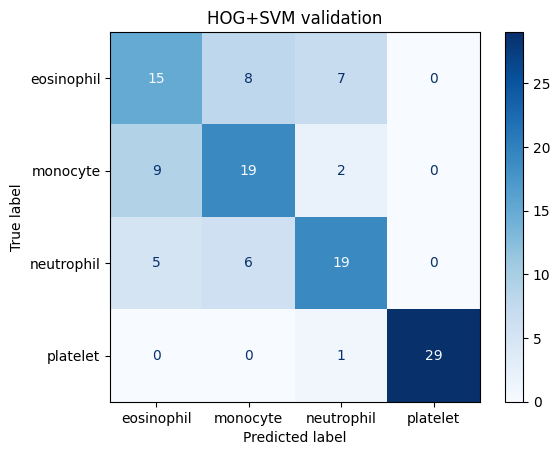

array([1, 5, 1, 5, 5, 5, 6, 1, 1, 1, 1, 5, 1, 5, 1, 1, 5, 1, 1, 5, 1, 1,
       1, 6, 6, 6, 1, 6, 6, 6, 5, 5, 1, 5, 5, 5, 1, 5, 6, 5, 5, 5, 5, 1,
       5, 5, 1, 5, 1, 5, 1, 6, 5, 5, 5, 1, 1, 5, 1, 5, 6, 5, 6, 1, 5, 6,
       6, 1, 6, 6, 5, 6, 6, 5, 5, 5, 1, 6, 6, 6, 6, 6, 6, 6, 1, 6, 6, 6,
       1, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 6, 7, 7, 7])

In [ ]:
def tune_svm(Xtr, ytr, Xva, yva):
    best = None
    for use_scaler in [True, False]:
        for C in [0.1, 1, 10]:
            steps = [StandardScaler()] if use_scaler else []
            steps.append(LinearSVC(C=C, max_iter=10000))
            clf = make_pipeline(*steps)
            clf.fit(Xtr, ytr)
            acc = accuracy_score(yva, clf.predict(Xva))
            print(f"scaler={use_scaler!s:<5} C={C:<5} val accuracy={acc:.4f}")
            if best is None or acc > best[0]:
                best = (acc, C, use_scaler, clf)
    print(f"Chosen: scaler={best[2]}, C={best[1]}, val accuracy={best[0]:.4f}")
    return best[1], best[3]

def report(clf, X, y, title):
    pred = clf.predict(X)
    print(f"{title}: accuracy={accuracy_score(y, pred):.4f}  macro-F1={f1_score(y, pred, average='macro'):.4f}")
    cm = confusion_matrix(y, pred, labels=CLASSES)
    ConfusionMatrixDisplay(cm, display_labels=[CLASS_NAMES[c] for c in CLASSES]).plot(cmap="Blues")
    plt.title(title); plt.show()
    return pred

hog_C, hog_clf = tune_svm(Xtr_h, tr_y, Xva_h, va_y)
report(hog_clf, Xva_h, va_y, "HOG+SVM validation")

## Q3(a). Normal SIFT keypoints
**Why this fails for an SVM:** an SVM needs a fixed-length vector per image, but detected keypoints vary in number from image to image, so the vectors would have different lengths.

Keypoints per image -> mean: 114.5, min: 12, max: 318
Images with zero keypoints: 0


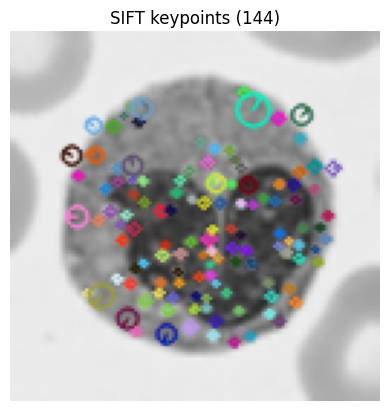

In [ ]:
sift = cv2.SIFT_create()

# (a) Normal SIFT keypoints on training images
kp_counts = []
for im in tr_X:
    kps, _ = sift.detectAndCompute(im, None)
    kp_counts.append(len(kps))
kp_counts = np.array(kp_counts)
print("Keypoints per image -> mean: %.1f, min: %d, max: %d" % (kp_counts.mean(), kp_counts.min(), kp_counts.max()))
print("Images with zero keypoints:", int((kp_counts == 0).sum()))

# Draw keypoints on one image
kps0, _ = sift.detectAndCompute(tr_X[0], None)
vis = cv2.drawKeypoints(tr_X[0], kps0, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
plt.imshow(vis); plt.title(f"SIFT keypoints ({len(kps0)})"); plt.axis("off"); plt.show()

## Q3(b). Fixed grid of keypoints
**Hand calculation of feature length:** 4 × 4 = 16 grid points, each with a 128-value descriptor. Total: 16 × 128 = **2048**.

In [ ]:
# (b) Fixed grid of keypoints
step = 128 // SIFT_GRID                          # 32
pts = [step // 2 + step * i for i in range(SIFT_GRID)]   # 16, 48, 80, 112
grid_kps = [cv2.KeyPoint(float(x), float(y), 32) for y in pts for x in pts]

def sift_grid_feats(imgs):
    out = []
    for im in imgs:
        _, des = sift.compute(im, grid_kps)
        assert des is not None and des.shape == (len(grid_kps), 128), "compute() dropped keypoints"
        out.append(des.reshape(-1))
    return np.array(out)

Xtr_s, Xva_s, Xte_s = sift_grid_feats(tr_X), sift_grid_feats(va_X), sift_grid_feats(te_X)
print("SIFT grid feature length:", Xtr_s.shape[1])

SIFT grid feature length: 2048


## Q3(c). SVM tuning and validation report
Same procedure as Q2(c), applied to the 2048-value SIFT vectors.

**Chosen:** scaler = [fill from Chosen line], C = [fill]
**Validation accuracy:** [fill]   **Macro-F1:** [fill]
**Most-confused pair (confusion matrix):** [fill]

scaler=True  C=0.1   val accuracy=0.7667
scaler=True  C=1     val accuracy=0.7583
scaler=True  C=10    val accuracy=0.7583


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


scaler=False C=0.1   val accuracy=0.7417


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


scaler=False C=1     val accuracy=0.7583


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:1249: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


scaler=False C=10    val accuracy=0.7500
Chosen: scaler=True, C=0.1, val accuracy=0.7667
SIFT+SVM validation: accuracy=0.7667  macro-F1=0.7594


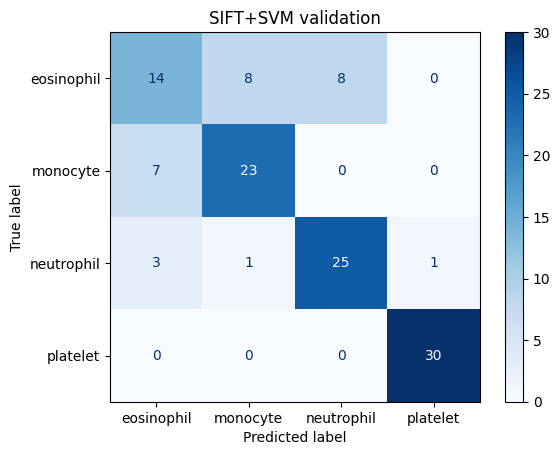

array([1, 6, 1, 6, 1, 1, 5, 5, 1, 1, 1, 5, 5, 5, 6, 1, 5, 5, 6, 6, 1, 6,
       1, 6, 1, 1, 1, 6, 1, 5, 5, 5, 5, 5, 5, 1, 5, 5, 5, 5, 5, 5, 5, 1,
       1, 5, 1, 5, 1, 5, 1, 5, 5, 5, 5, 1, 5, 5, 5, 5, 6, 6, 6, 1, 6, 6,
       6, 6, 6, 6, 6, 6, 6, 6, 6, 7, 6, 6, 6, 1, 6, 6, 6, 5, 6, 1, 6, 6,
       6, 6, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7,
       7, 7, 7, 7, 7, 7, 7, 7, 7, 7])

In [ ]:
sift_C, sift_clf = tune_svm(Xtr_s, tr_y, Xva_s, va_y)
report(sift_clf, Xva_s, va_y, "SIFT+SVM validation")

## Q4. Robustness
**Prediction (write before running this cell):** HOG will lose more under [fill]; SIFT will lose more under [fill]. Reason: [fill].

Both models are frozen. Rotated (20°) and noisy (σ = 0.05) versions of the test set are made before feature extraction.

**Results (test set)**
| Model | Clean | Rotated | Noisy |
|---|---|---|---|
| HOG + SVM | [fill] | [fill] | [fill] |
| SIFT + SVM | [fill] | [fill] | [fill] |

**Was the prediction correct? (three sentences):** [fill]

In [ ]:
def rotate20(im):
    M = cv2.getRotationMatrix2D((64, 64), 20, 1.0)
    return cv2.warpAffine(im, M, (128, 128))

noise_rng = np.random.default_rng(SEED)
def add_noise(im):
    x = im / 255.0 + noise_rng.normal(0, 0.05, im.shape)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)

te_rot = np.array([rotate20(im) for im in te_X])
te_noise = np.array([add_noise(im) for im in te_X])

# Frozen models: evaluate on clean, rotated and noisy test images
results = {}
for name, feat_fn, clf in [("HOG + SVM", hog_feats, hog_clf), ("SIFT + SVM", sift_grid_feats, sift_clf)]:
    accs = {}
    for case, imgs in [("clean", te_X), ("rotated", te_rot), ("noisy", te_noise)]:
        accs[case] = accuracy_score(te_y, clf.predict(feat_fn(imgs)))
    results[name] = accs

print(f"{'Model':<12}{'Clean':>10}{'Rotated':>10}{'Noisy':>10}")
for name, a in results.items():
    print(f"{name:<12}{a['clean']:>10.4f}{a['rotated']:>10.4f}{a['noisy']:>10.4f}")


--- ROBUSTNESS EVALUATION TABLE ---
Model           | Clean accuracy  | Rotated accuracy | Noisy accuracy 
----------------------------------------------------------------------
HOG + SVM       | 0.7333          | 0.5667            | 0.5417
SIFT + SVM      | 0.7500          | 0.4917            | 0.7583


## Demo: predictions on validation images
Two validation images per class, with true label and each model's prediction. Validation data only.

#   True        HOG+SVM     SIFT+SVM    
0   eosinophil  eosinophil  eosinophil  
1   eosinophil  monocyte    neutrophil  
2   monocyte    monocyte    monocyte    
3   monocyte    monocyte    monocyte    
4   neutrophil  neutrophil  neutrophil  
5   neutrophil  monocyte    neutrophil  
6   platelet    platelet    platelet    
7   platelet    platelet    platelet    


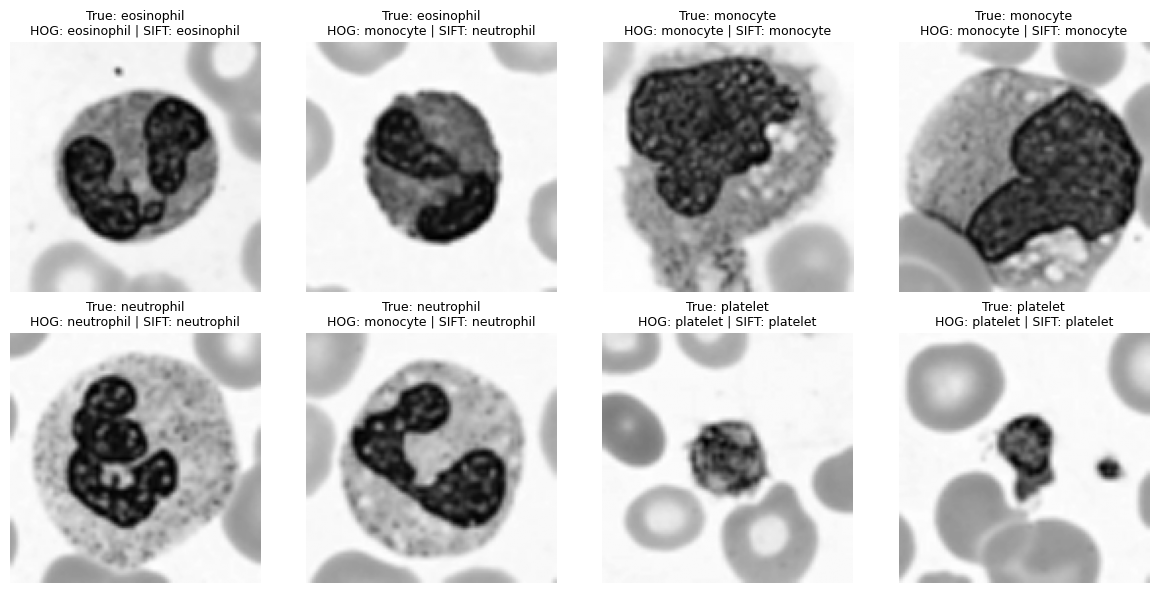

In [ ]:
# Test a few images: show the image, true class, and both model predictions
def predict_one(imgs, labels_idx=None):
    h_pred = hog_clf.predict(hog_feats(imgs))
    s_pred = sift_clf.predict(sift_grid_feats(imgs))
    return h_pred, s_pred

# Pick 2 validation images per class
sample_idx = []
for c in CLASSES:
    sample_idx += list(np.where(va_y == c)[0][:2])
sample_idx = np.array(sample_idx)

imgs = va_X[sample_idx]
true = va_y[sample_idx]
h_pred, s_pred = predict_one(imgs)

# Print a text table
print(f"{'#':<4}{'True':<12}{'HOG+SVM':<12}{'SIFT+SVM':<12}")
for k in range(len(sample_idx)):
    print(f"{k:<4}{CLASS_NAMES[true[k]]:<12}"
          f"{CLASS_NAMES[h_pred[k]]:<12}"
          f"{CLASS_NAMES[s_pred[k]]:<12}")

# Show the images with predictions
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, k in zip(axes.ravel(), range(len(sample_idx))):
    ax.imshow(imgs[k], cmap="gray")
    ax.set_title(f"True: {CLASS_NAMES[true[k]]}\n"
                 f"HOG: {CLASS_NAMES[h_pred[k]]} | SIFT: {CLASS_NAMES[s_pred[k]]}",
                 fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

## AI log
| Item | Entry |
|---|---|
| Prompt (one line) | [fill] |
| What I changed | [e.g. compared StandardScaler on validation and kept the better option] |
| How I checked it | [e.g. printed feature lengths 1764 and 2048; class counts 100/30/30 per class] |

## Q5. Short answers
**(a) Why HOG uses block normalisation:** [fill]
**(b) Why choosing C on the test set is wrong:** [fill]
**(c) Most-confused classes and why grayscale makes it harder:** [fill]